# Часть 1. Проверка гипотезы в Python и составление аналитической записки

# Анализ пользовательской активности и результатов A/B-теста

## Цели и задачи проекта



Цель проекта:

Проверить статистическую гипотезу о различии среднего времени активности пользователей приложения между Санкт-Петербургом и Москвой, а именно: действительно ли пользователи из Санкт-Петербурга проводят в приложении больше времени за чтением и прослушиванием книг.

Задачи: загрузить данные, осмотреть, проверить корректность типов, наличие пропусков и дубликатов. Проверить гипотезу в Python (предворительно осомотреть данные, выбрать необходимый тип теста). Составить аналитическую записку, где предоставить краткое описание проведенной работы, выводы и рекомендации. 

## Описание данных

Таблица `yandex_knigi_data` содержит данные об активности пользователей и состоит из следующих полей:

`city` - город пользователя;

`puid` - изначальный идентификатор пользователя;

`hours` - сумма часов, проведенных пользователем в приложении;

## Содержимое проекта

1. Загрузка данных и знакомство с ними
2. Проверка гипотезы в Python
3. Аналитическая записка

**Импорт библиотек**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## 1. Загрузка данных и знакомство с ними

In [2]:
df = pd.read_csv("https://code.s3.yandex.net/datasets/yandex_knigi_data.csv", usecols=["city", "puid", "hours"])
df.head()

,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    8784 non-null   object 
 1   puid    8784 non-null   int64  
 2   hours   8784 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 206.0+ KB


In [4]:
missing_string = df.isna().all(axis=1).sum()
f'Полностью пустых строк в датасете: {missing_string}'

'Полностью пустых строк в датасете: 0'

In [5]:
strings = df.notna().any(axis=1).sum()
f'Количество не пустых строк в датасете: {strings}'

'Количество не пустых строк в датасете: 8784'

Во всех столбцах 8784 строки, что совпадает с общим количеством строк датасета, следовательно, пропуски не обнаружены. 

In [6]:
duplicates = df.duplicated().sum()
f'Количество явных дубликатов в датасете: {duplicates}'

'Количество явных дубликатов в датасете: 0'

In [7]:
duplicates_puid = df['puid'].duplicated().sum()
f'Количество дубликатов по puid: {duplicates_puid}'

'Количество дубликатов по puid: 244'

In [8]:
duplicates_puid = df[df.duplicated(subset='puid', keep=False)]

print(f'Количество строк с повторяющимися id: {len(duplicates_puid)}')
duplicates_puid.sort_values('puid').head()

Количество строк с повторяющимися id: 488


,city,puid,hours
35,Москва,2637041,10.317371
6247,Санкт-Петербург,2637041,3.883926
134,Москва,9979490,32.415573
6274,Санкт-Петербург,9979490,1.302997
145,Москва,10597984,42.931506


In [9]:
duplicates_puid_city = df[df.duplicated(subset=['puid', 'city'], keep=False)]

print(f'Количество строк с повторяющимися id и городом : {len(duplicates_puid_city)}')

Количество строк с повторяющимися id и городом : 0


Можно сделать вывод, что повторяющийся puid имеется толькр у пользователей, проявлявших активность и в Санкт-Петербурке, и в Москве, такие пользователи нерелевантны для проверки гипотезы, следовательно их следует удалить. 

Удаление дубликатов:

In [10]:
df = df[~df.duplicated('puid', keep=False)].copy()

Данные обработаны, удалены дубликаты, неверных типов данных и пропусков не обнаружено. 

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы.

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

Размеры групп по городам: 

In [11]:
df.groupby('city')['puid'].count()

city
Москва             5990
Санкт-Петербург    2306
Name: puid, dtype: int64

In [12]:
df.groupby('city')['hours'].describe()

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Москва,5990.0,10.848192,36.925622,0.000022,0.057042,0.888232,5.933439,857.209373
Санкт-Петербург,2306.0,11.264433,39.831755,0.000025,0.060173,0.875355,6.138424,978.764775


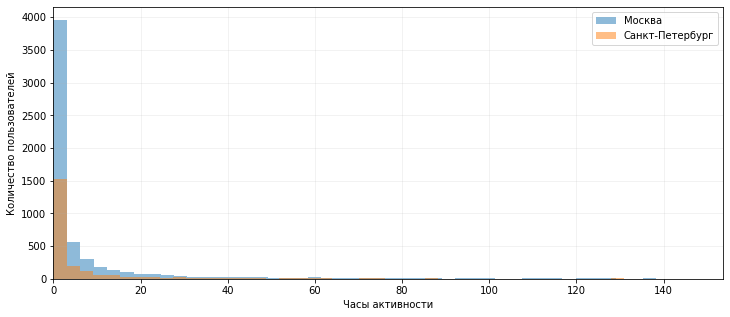

In [13]:
moscow = df.loc[df['city'] == 'Москва', 'hours']
spb = df.loc[df['city'] == 'Санкт-Петербург', 'hours']

all_data = np.concatenate([moscow, spb])
x_max = np.percentile(all_data, 99)

plt.figure(figsize=(12, 5))

plt.hist(moscow[moscow <= x_max], bins=50, alpha=0.5, label='Москва')
plt.hist(spb[spb <= x_max], bins=50, alpha=0.5, label='Санкт-Петербург')

plt.xlim(0, x_max)

plt.xlabel('Часы активности')
plt.ylabel('Количество пользователей')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

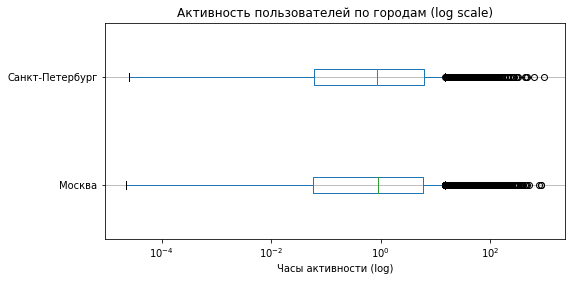

In [14]:


df.boxplot(column='hours', by='city', figsize=(8, 4), vert=False)

plt.xscale('log')
plt.title('Активность пользователей по городам (log scale)')
plt.xlabel('Часы активности (log)')
plt.ylabel('')
plt.suptitle('')
plt.grid(axis='x', which='both', alpha=0.3)
plt.show()

Можно отметить, что распределение неравномерное, и количество пользователей сильно отличается в Москве и Санкт-Петербурге, следовательно для проверки гипотезы лучше использовать тест Уэлча. Поскольку у нас имеются нулевая и альтернативная гипотезы, используем односторонний тест. 

In [15]:
from scipy import stats

moscow = df.loc[df['city'] == 'Москва', 'hours']
spb = df.loc[df['city'] == 'Санкт-Петербург', 'hours']

results = stats.ttest_ind(
    spb,
    moscow,
    equal_var=False
)

print('Статистика t-теста:', results.statistic)
print('Двусторонний p-value:', results.pvalue)

Статистика t-теста: 0.43499237928704976
Двусторонний p-value: 0.6635919203695009


In [16]:
p_value_one_sided = results.pvalue / 2

print('Односторонний p-value:', p_value_one_sided)

alpha = 0.05

if (results.statistic > 0) and (p_value_one_sided < alpha):
    print('Отвергаем H0')
else:
    print('Не удалось отвергнуть H0')

Односторонний p-value: 0.33179596018475044
Не удалось отвергнуть H0


## 3. Аналитическая записка

Был проведен статистический анализ - односторонний t-тесть Уэлча). Он не выявил значимого превышения среднего времени активности пользователей Санкт-Петербурга над Москвой (p = 0.332 > 0.05). Следовательно, гипотеза о более высокой активности пользователей Санкт-Петербурга не подтверждается на имеющихся данных.
Предполагаемые причины: 

1. Пользователи из Москвы и Санкт-Петербурга имеют схожее поведение и слушают в среднем схожее количество книг. 

2. Выборка данных неравномерна, из-за чего в обоих группах присутствуют пользователи с активностью аномально выше среднего, что может негативно влиять на точность анализа. 

3. Данных недостаточно для обнаружения небольшой корреляции. И есть вероятность, что при проведении теста на расширенной выборке, будет обнаружена небольшая зависимость активности прользователей от города. 

Рекомендуется провести анализ других факторов, влияющих на активность пользователя. 

----

# Часть 2. Анализ результатов A/B-тестирования

Интернет-магазин BitMotion Kit продаёт геймифицированные товары для здорового образа жизни. Чтобы упростить взаимодействие с сайтом и повысить конверсию в покупку, компания разработала новый интерфейс и провела A/B-тестирование.

## 1. Цели исследования

Необходимо определить результаты A/B теста по внедрению нового интерфейса сайта для интернет-магазина BitMotion Kit. Оценить корректность данных, корректность проведения тестов и сделать вывод о необходимости внедрения нового интерфейса для всех пользователей. 

## 2. Загрузка и проверка целостности данных

**Описание данных**

Данные состоят из таблицы участников теста `ab_test_participants.csv` и архива с одним файлом, в котором собраны события 2020 года `ab_test_events.zip`

Структура таблицы `ab_test_participants`:

``user_id`` — идентификатор пользователя;

``group`` — группа пользователя;

``ab_test`` — название теста;

``device`` — устройство, с которого происходила регистрация.

Структура архива `ab_test_events.`:

`user_id` — идентификатор пользователя;

`event_dt` — дата и время события;

`event_name` — тип события;

`details` — дополнительные данные о событии (в столбце сожержатся данные в зависимоси от данных в столбце `event_name`, для события `registration` указана стоимость привлечения клиента, для события `purchase` стоимость покупки, для других событий ZONE_CODE[N], где [N] номер региона, расшифровывающийся по указанной ниже таблице):

<details>
<summary>(нажмите для раскрытия таблицы)</summary>

<br>

<table>
    <thead>
        <tr>
            <th>ID</th>
            <th>Код</th>
            <th>Зона</th>
        </tr>
    </thead>
    <tbody>
        <tr><td>0</td><td>ZONE_CODE00</td><td>None</td></tr>
        <tr><td>1</td><td>ZONE_CODE01</td><td>EU</td></tr>
        <tr><td>2</td><td>ZONE_CODE02</td><td>CIS</td></tr>
        <tr><td>3</td><td>ZONE_CODE03</td><td>EU, CIS</td></tr>
        <tr><td>4</td><td>ZONE_CODE04</td><td>APAC</td></tr>
        <tr><td>5</td><td>ZONE_CODE05</td><td>EU, APAC</td></tr>
        <tr><td>6</td><td>ZONE_CODE06</td><td>CIS, APAC</td></tr>
        <tr><td>7</td><td>ZONE_CODE07</td><td>EU, CIS, APAC</td></tr>
        <tr><td>8</td><td>ZONE_CODE08</td><td>N.America</td></tr>
        <tr><td>9</td><td>ZONE_CODE09</td><td>EU, N.America</td></tr>
        <tr><td>10</td><td>ZONE_CODE10</td><td>CIS, N.America</td></tr>
        <tr><td>11</td><td>ZONE_CODE11</td><td>EU, CIS, N.America</td></tr>
        <tr><td>12</td><td>ZONE_CODE12</td><td>APAC, N.America</td></tr>
        <tr><td>13</td><td>ZONE_CODE13</td><td>EU, APAC, N.America</td></tr>
        <tr><td>14</td><td>ZONE_CODE14</td><td>CIS, APAC, N.America</td></tr>
        <tr><td>15</td><td>ZONE_CODE15</td><td>EU, CIS, APAC, N.America</td></tr>
    </tbody>
</table>

</details>

**Загрузка данных**

In [17]:
participants = pd.read_csv("https://code.s3.yandex.net/datasets/ab_test_participants.csv")
events = pd.read_csv("https://code.s3.yandex.net/datasets/ab_test_events.zip", low_memory=False)

In [18]:
participants.head()

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


In [19]:
participants.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB


In [20]:
strings1 = len(participants['user_id'])
f'Количество строк таблице участников теста: {strings1}'

'Количество строк таблице участников теста: 14525'

In [21]:
events.head()

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


In [22]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   user_id     787286 non-null  object
 1   event_dt    787286 non-null  object
 2   event_name  787286 non-null  object
 3   details     249022 non-null  object
dtypes: object(4)
memory usage: 24.0+ MB


In [23]:
strings2 = len(events['user_id'])
f'Количество строк таблице событий 2020 года: {strings2}'

'Количество строк таблице событий 2020 года: 787286'

**Работа с пропусками**

In [24]:
missing_string1 = participants.isna().all(axis=1).sum()
missing_string2 = events.isna().all(axis=1).sum()
missing_string = missing_string1 + missing_string2
f'Количество полностью пустых строк в таблицах: {missing_string}'

'Количество полностью пустых строк в таблицах: 0'

Можно сделать вывод, что пропуски присутствуют только в датафрейме с событиями 2020 года, исключительно в столбце ``details``, что обусловлено тем, что не для всех событий существует дополнительная информация, и с этим нет необходимости ничего делать. Но это стоит учесть, если понадобится собрать данные по регионам событий, так как они содержатся не для всей таблицы.

**Приведение к необходимым типам данных:**

In [25]:
events['event_dt'] = pd.to_datetime(events['event_dt'], errors='coerce')

Некорректный тип данных присутствовал только в строке ``event_dt`` датафрейма с событиями за 2020 год. 

**Проверка на наличие явных дубликатов**

В таблице с данными пользователей:

In [26]:
participants.duplicated().sum()

0

В таблице с событиями за 2020 год:

In [27]:
events.duplicated().sum()

36318

Удаление явных дубликатов:

In [28]:
events = events.drop_duplicates()

Данные были обработаны: приведены к необходимому типу, удалены явные дубликаты, критических пропусков не обнаружено.

## 3. Проверка корректности проведения A/B-теста

### 3.1. Распределение пользователей по группам и пересечения с другим тестом

In [29]:
interface_test = participants.query('ab_test == "interface_eu_test"')

print('Количество участников теста:', interface_test['user_id'].nunique())

Количество участников теста: 10850


Количество участников теста по группам и их доля:

In [30]:
group_sizes = (
    interface_test.groupby('group')['user_id']
    .nunique()
    .reset_index()
)

group_sizes['share'] = (
    group_sizes['user_id']
    / group_sizes['user_id'].sum()
)

group_sizes

,group,user_id,share
0,A,5383,0.496129
1,B,5467,0.503871


Пользователи распределены между группами A и B практически равномерно. Существенного перекоса в численности групп не наблюдается, что соответствует требованиям корректного проведения A/B-теста.

In [31]:
interface_users = set(
    participants.query('ab_test == "interface_eu_test"')['user_id']
)

recommender_users = set(
    participants.query('ab_test == "recommender_system_test"')['user_id']
)

intersection = interface_users & recommender_users

print('Пользователей в обоих тестах:', len(intersection))

Пользователей в обоих тестах: 887


Обнаружено 887 пользователей, участвующих одновременно в обоих тестах. Такое пересечение может искажать результаты A/B-теста, поскольку на поведение пользователей одновременно влияют два экспериментальных изменения. Необходимо исключить их из результатов теста. 

In [32]:
participants = participants[
    (participants['ab_test'] == 'interface_eu_test')
    &
    (~participants['user_id'].isin(intersection))
].copy()
participants['ab_test'].value_counts()
events = events[
    events['user_id'].isin(participants['user_id'])
].copy()
interface_users = set(
    participants.query('ab_test == "interface_eu_test"')['user_id']
)

recommender_users = set(
    participants.query('ab_test == "recommender_system_test"')['user_id']
)

intersection = interface_users & recommender_users

print('Пользователей в обоих тестах:', len(intersection))

Пользователей в обоих тестах: 0


In [33]:
users_in_both_groups = (
    interface_test.groupby('user_id')['group']
    .nunique()
    .reset_index()
)

users_in_both_groups = users_in_both_groups[
    users_in_both_groups['group'] > 1
]

print(
    'Пользователей одновременно в A и B:',
    len(users_in_both_groups)
)

Пользователей одновременно в A и B: 0


Пользователей, находящихся одновременно в двух группах, не обнаружено. 

### 3.2. Анализ пользовательской активности

**Отбор событий участников теста**

In [34]:
test_users = interface_test['user_id'].unique()

print('Количество участников теста:',
      len(test_users))
test_events = events[
    events['user_id'].isin(test_users)
].copy()

print('Количество событий участников теста:',
      len(test_events))

display(test_events.head())

Количество участников теста: 10850
Количество событий участников теста: 68074


,user_id,event_dt,event_name,details
64672,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0
64946,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8
66585,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32
67873,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48
67930,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0


**Горизонт анализа: первые семь дней после регистрации**

In [35]:
registration_dates = (
    test_events[test_events['event_name'] == 'registration']
    [['user_id', 'event_dt']]
    .rename(columns={'event_dt': 'registration_dt'})
)
test_events = test_events.merge(
    registration_dates,
    on='user_id',
    how='left'
)
test_events['lifetime'] = (
    test_events['event_dt']
    - test_events['registration_dt']
)
test_events['lifetime_days'] = (
    test_events['lifetime'].dt.total_seconds()
    / 86400
)
test_events_7d = test_events[
    (test_events['lifetime'] >= pd.Timedelta(0))
    &
    (test_events['lifetime'] <= pd.Timedelta(days=7))
].copy()

print('Событий до фильтрации:', len(test_events))
print('Событий после фильтрации:', len(test_events_7d))

print('Максимальный лайфтайм:',
      test_events_7d['lifetime'].max())

Событий до фильтрации: 68074
Событий после фильтрации: 58692
Максимальный лайфтайм: 6 days 23:58:10


В соответствии с техническим заданием был определён горизонт анализа — 7 дней с момента регистрации пользователя. Для каждого события рассчитан лайфтайм как разница между временем события и временем регистрации. В дальнейший анализ включены только события, совершённые в течение первых семи суток после регистрации, что позволяет корректно оценить влияние изменений интерфейса на поведение новых пользователей.

**Оценка достаточности выборки**

Параметры расчёта:

- Базовая конверсия — 30%.
- Мощность теста — 80%.
- Уровень доверия — 95%.

Необходимый объем выборки:

In [36]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

baseline = 0.30
effect = 0.33  # +10%

effect_size = proportion_effectsize(baseline, effect)

analysis = NormalIndPower()

sample_size_per_group = analysis.solve_power(
    effect_size=effect_size,
    power=0.80,
    alpha=0.05,
    ratio=1
)

sample_size_per_group

3761.596974012117

Фактический объем выборки:

In [37]:
actual_sample = participants.groupby('group')['user_id'].nunique()
actual_sample

group
A    4952
B    5011
Name: user_id, dtype: int64

**Расчёт числа пользователей и покупателей по группам**

Общее количество посетителей на группу:

In [38]:
total_users = participants.groupby('group')['user_id'].nunique()
total_users

group
A    4952
B    5011
Name: user_id, dtype: int64

Количество пользователей, совершивших покупку по группам:

In [39]:
purchases = events[events['event_name'] == 'purchase']
buyers_by_group = (
    participants.merge(purchases[['user_id']], on='user_id')
    .groupby('group')['user_id']
    .nunique()
)

buyers_by_group

group
A    1638
B    1782
Name: user_id, dtype: int64

In [40]:
summary = pd.DataFrame({
    'пользователи': total_users,
    'покупатели': buyers_by_group
})

summary['конверсия в покупку'] = summary['покупатели'] / summary['пользователи']

summary

,пользователи,покупатели,конверсия в покупку
group,,,
A,4952,1638,0.330775
B,5011,1782,0.355618


**Предварительный вывод о конверсии**

В группе B конверсия больше на 2,48 п.п., что является повышением конверсии на 7,5% относительно оригинальной группы. Что говорит об умеренном, но четко заметным, изменении в поведении пользователей в новом интерфейсе. 

## 4. Оценка результатов A/B-тестирования

**Статистическая проверка различий в конверсии**

Проведем z-тест, так как он наиболее релевантен для нашей выборки, так как она достаточного размера и является равномерной.

In [41]:
from statsmodels.stats.proportion import proportions_ztest

buyers = np.array([1782, 1638])  # сначала группа B, затем A
total = np.array([5011, 4952])

stat, p_value = proportions_ztest(
    count=buyers,
    nobs=total,
    alternative='larger'
)

print('z-статистика:', stat)
print('p-value:', p_value)

alpha = 0.05

if p_value < alpha:
    print('Отвергаем H0')
else:
    print('Не отвергаем H0')

z-статистика: 2.611175555675904
p-value: 0.004511578024761222
Отвергаем H0


Нулевая гипотеза о равенстве конверсий отвергается.

Это означает, что различия между группами A и B статистически значимы.

**Итоговый вывод и рекомендации**

При планировании теста предполагалось обнаружение эффекта порядка 10% относительно базовой конверсии. Фактически был получен прирост конверсии на 7.5% относительно контрольной группы (2.48 процентного пункта). Таким образом, направление эффекта соответствует ожидаемому, однако его величина оказалась несколько ниже плановой.

Для принятия решения о введении обновления интерфейса рекомендуется провести анализ других критериев, изменившихся в результате A/B теста (например, изменились ли прирост выручки и размер среднего чека), чтобы лучше оценить будет ли данное решение окупаемым и целесообразным. 

<a class="anchor" id="1-bullet"></a>
<div style="border:solid Chocolate 2px; padding: 40px">
Люда, спасибо за работу. Осталось исправить несколько комментариев и можно идти к заказчику. Молодец! 
   
   
    Что необходимо доработать: 
    
    1. Провести А/В-тест.
    
    2. Оформить вывод.
   
    3. Рекомендую:
    - импортировать библиотеки вначале проекта.
 
    
    Жду новую версию проекта!)
    
[В начало](#3-bullet)